# 📖 Text → Tokens (Intermediate): Tokenizing a Whole Novel

**Course:** LLM from Scratch · **Topic 01:** Text to Vectors Basics · **Lesson 02:** Turning Text into Numeric Tokens

In `text2tokens.ipynb` we built a word-level tokenizer for **three sentences**. Here we scale the same idea up to a **complete novel**, *Frankenstein* by Mary Shelley (Project Gutenberg eBook #84), and look at what changes when the text is real, long and messy.

```text
 Raw book (446,582 characters)
     │  clean: fix encoding junk, drop non-ASCII, digits, lowercase
     ▼
 Clean text
     │  split on punctuation + whitespace, drop 1-letter words
     ▼
 Words (73,888)  ──►  Vocabulary (7,243 unique)  ──►  word2idx / idx2word
                                                           │
                                   encoder / decoder  ◄────┘
                                           │
               random tokens · Brownian-walk tokens · statistics · unknown words
```

### 🗺️ What this notebook covers

| # | Section | Key idea |
|---|---------|----------|
| 1 | Setup | libraries + a fixed random seed |
| 2 | Get the book | download raw text over HTTP |
| 3 | Clean the text | remove encoding artefacts, non-ASCII, digits, case |
| 4 | Split into words | regex on punctuation + whitespace |
| 5 | Build the vocabulary | `sorted(set(words))`, `word2idx`, `idx2word` |
| 6 | Encoder & decoder | text ↔ integer IDs, round-trip test |
| 7 | 📊 Seeing the story as numbers | a sentence plotted as token IDs |
| 8 | Random & Brownian tokens | "language models" with zero knowledge |
| 9 | 📊 Word-length distribution | how long are English words? |
| 10 | 📊 Word frequencies, Zipf & Heaps | why vocabularies explode |
| 11 | Encoding a new sentence | the out-of-vocabulary (OOV) problem |
| 12 | The `<|unk|>` token | a fallback so the encoder never crashes |
| 13 | Summary | what we learned and what comes next |

---
## 1 · Setup

* **NumPy** stores token IDs as integer arrays and does the counting.
* **requests** downloads the book; **re** (regular expressions) does the cleaning and splitting.
* **Matplotlib** draws the plots (new in this version).

A fixed random seed makes the "random token" sections reproducible: every run decodes the same random words.

In [1]:
# typical libraries...
import numpy as np

# for importing and working with texts
import requests
import re
import string

# for visualisation
import matplotlib.pyplot as plt
from collections import Counter

# reproducible randomness (same "random" tokens every run)
np.random.seed(42)

# one consistent, quiet plot style for the whole notebook
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--',
    'axes.titleweight': 'bold', 'font.size': 10,
})
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#8a8984'

---
## 2 · Get the book 📥

`requests.get(url)` sends an HTTP GET request and returns a `Response`; `.text` is the body decoded to a Python `str`.

The raw file is **not** just the story. It starts with the Project Gutenberg header (title, licence, credits) and a table of contents, and it ends with a long licence section. We keep all of it here for simplicity, but in a serious corpus you would cut the text between the `*** START OF ...` and `*** END OF ...` markers.

Notice the `\r\n` sequences in the output: Windows-style line breaks (carriage return + newline). They are just whitespace for us, and the next step removes them.

In [2]:
# get raw text from internet
book = requests.get('https://www.gutenberg.org/cache/epub/84/pg84.txt')

# extract just the text and have a look at it
text = book.text
print(type(text))
print(f'{len(text):,} characters')

text[:2000]

<class 'str'>
446,582 characters


'The Project Gutenberg eBook of Frankenstein; or, the modern prometheus\r\n    \r\nThis eBook is for the use of anyone anywhere in the United States and\r\nmost other parts of the world at no cost and with almost no restrictions\r\nwhatsoever. You may copy it, give it away or re-use it under the terms\r\nof the Project Gutenberg License included with this eBook or online\r\nat www.gutenberg.org. If you are not located in the United States,\r\nyou will have to check the laws of the country where you are located\r\nbefore using this eBook.\r\n\r\nTitle: Frankenstein; or, the modern prometheus\r\n\r\nAuthor: Mary Wollstonecraft Shelley\r\n\r\n\r\n        \r\nRelease date: October 1, 1993 [eBook #84]\r\n                Most recently updated: February 10, 2026\r\n\r\nLanguage: English\r\n\r\nOther information and formats: www.gutenberg.org/ebooks/84\r\n\r\nCredits: Judith Boss, Christy Phillips, Lynn Hanninen and David Meltzer. HTML version by Al Haines.\r\n        Further corrections by Me

---
## 3 · Clean the text 🧹

Real text contains characters that would pollute the vocabulary. We clean in two passes.

### 3a · Replace encoding artefacts with spaces

When UTF-8 bytes are decoded with the wrong character set, a curly quote `“` (bytes `E2 80 9C`) turns into the three characters `â\x80\x9c` (this is called **mojibake**). The list below targets those patterns plus newlines and the `_` used for *italics* in Gutenberg files.

| Pattern | What it was | Why remove it |
|---------|-------------|---------------|
| `\r\n` | line break | layout, not language |
| `â\x80\x9c` / `â\x80\x9d` | “ ” curly double quotes | punctuation |
| `â\x80\x98` / `â\x80\x99` | ‘ ’ curly single quote / apostrophe | punctuation |
| `â\x80\x94` | — em dash | punctuation |
| `_` | Gutenberg's marker for italics (`_word_`) | formatting |

> 💡 In this run `requests` decoded the file correctly as UTF-8, so the mojibake patterns find nothing and the real curly quotes survive this pass. They are removed anyway in step 3b, because they are non-ASCII. The list is kept because it protects you when a server reports the wrong encoding.

In [3]:
# character strings to replace with space
strings2replace = [
    '\r\n\r\nâ\x80\x9c',  # new paragraph + open quote
    'â\x80\x9c',          # open quote
    'â\x80\x9d',          # close quote
    '\r\n',               # new line
    'â\x80\x94',          # em dash
    'â\x80\x99',          # single apostrophe
    'â\x80\x98',          # single quote
    '_',                  # underscore, used for stressing (italics)
]

# e.g., 'â\x80\x9d'.encode('latin1').decode('utf8')  ->  '”'

# use regular expression (re) to replace those strings with space
for str2match in strings2replace:
    regexp = re.compile(r'%s' % str2match)
    text = regexp.sub(' ', text)

print(f'{len(text):,} characters after replacing artefacts')

438,841 characters after replacing artefacts


### 3b · Remove non-ASCII characters and digits, then lowercase

| Regex | Meaning | Effect |
|-------|---------|--------|
| `[^\x00-\x7F]+` | one or more characters **outside** the ASCII range | curly quotes, dashes, accented letters → space |
| `\d+` | one or more digits | `1993`, `24`, `11th` → removed |
| `.lower()` | — | `The` and `the` become one token |

> ⚠️ **Small fix vs. the original:** the digit pattern is now written as a raw string, `r'\d+'`. Without the `r`, Python 3.12+ prints `SyntaxWarning: invalid escape sequence '\d'`. The result is the same, but raw strings are the correct habit for every regex.

Notice in the output how removing digits leaves gaps such as `chapter   chapter` (the chapter numbers are gone) and `dec. th,` (from *Dec. 11th*).

In [4]:
# remove non-ASCII characters
text = re.sub(r'[^\x00-\x7F]+', ' ', text)

# remove numbers  (raw string -> no escape-sequence warning)
text = re.sub(r'\d+', '', text)

# and make everything lower-case
text = text.lower()

# let's have a look!
text[:2000]

'the project gutenberg ebook of frankenstein; or, the modern prometheus      this ebook is for the use of anyone anywhere in the united states and most other parts of the world at no cost and with almost no restrictions whatsoever. you may copy it, give it away or re-use it under the terms of the project gutenberg license included with this ebook or online at www.gutenberg.org. if you are not located in the united states, you will have to check the laws of the country where you are located before using this ebook.  title: frankenstein; or, the modern prometheus  author: mary wollstonecraft shelley            release date: october ,  [ebook #]                 most recently updated: february ,   language: english  other information and formats: www.gutenberg.org/ebooks/  credits: judith boss, christy phillips, lynn hanninen and david meltzer. html version by al haines.         further corrections by menno de leeuw.   *** start of the project gutenberg ebook frankenstein; or, the modern p

---
## 4 · Split the text into words ✂️

`string.punctuation` is the 32 ASCII punctuation characters. We put them, plus `\s` (any whitespace), inside a character class `[...]` with `+` ("one or more"). `re.split` then cuts the text wherever a run of punctuation or spaces occurs:

```text
"frankenstein; or, the modern"  ──re.split──►  ['frankenstein', 'or', 'the', 'modern']
```

Then two filters:

1. **`item.strip()`** drops the empty strings that appear at the start/end of the split.
2. **`len(item) > 1`** drops one-letter "words". This removes noise such as the `s` left over from `victor's` → `victor`, `s`, but it **also removes real words `i` and `a`**. That is a design decision with a cost, and we will meet it again in section 11.

> ⚠️ **Small fix:** `\s` inside an f-string also triggers the escape warning, so the pattern is now built with an `rf'...'` (raw f-string).

In [5]:
# split by punctuation
print(string.punctuation)
puncts4re = rf'[{string.punctuation}\s]+'

words = re.split(puncts4re, text)
words = [item.strip() for item in words if item.strip()]

# remove single-character words
words = [item for item in words if len(item)>1]

# let's have a look
print(words[:50])

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
['the', 'project', 'gutenberg', 'ebook', 'of', 'frankenstein', 'or', 'the', 'modern', 'prometheus', 'this', 'ebook', 'is', 'for', 'the', 'use', 'of', 'anyone', 'anywhere', 'in', 'the', 'united', 'states', 'and', 'most', 'other', 'parts', 'of', 'the', 'world', 'at', 'no', 'cost', 'and', 'with', 'almost', 'no', 'restrictions', 'whatsoever', 'you', 'may', 'copy', 'it', 'give', 'it', 'away', 'or', 're', 'use', 'it']


---
## 5 · Build the vocabulary 📚

The **vocabulary** (or *lexicon*) is the set of unique tokens the model knows.

* `set(words)` removes duplicates.
* `sorted(...)` puts them in alphabetical order, so the same text always produces the **same IDs** (a `set` has no guaranteed order).

Then two dictionaries make the mapping reversible:

| Dictionary | Direction | Used by |
|------------|-----------|---------|
| `word2idx` | word → integer | the **encoder** |
| `idx2word` | integer → word | the **decoder** |

In [6]:
# create the vocab! (set of unique words)
vocab = sorted(set(words))

# convenience variables for later
nWords = len(words)
nLex = len(vocab)

print(f'{nWords:,} words')
print(f'{nLex:,} unique tokens')
print(f'each unique word appears {nWords/nLex:.1f} times on average')

73,888 words
7,243 unique tokens
each unique word appears 10.2 times on average


In [7]:
word2idx = {w:i for i,w in enumerate(vocab)}
idx2word = {i:w for i,w in enumerate(vocab)}

# print out every 87th entry: IDs are just alphabetical positions
for i in list(word2idx.items())[0:10000:87]:
    print(i)

('abandon', 0)
('acted', 87)
('aggravation', 174)
('amphitheatre', 261)
('apprehensions', 348)
('assassinated', 435)
('avail', 522)
('bed', 609)
('bitter', 696)
('brand', 783)
('call', 870)
('chairs', 957)
('circumstance', 1044)
('comfortless', 1131)
('conciliating', 1218)
('constant', 1305)
('correspondence', 1392)
('culled', 1479)
('debts', 1566)
('dense', 1653)
('detain', 1740)
('disclosed', 1827)
('disunion', 1914)
('drunken', 2001)
('elevating', 2088)
('enigmatic', 2175)
('eve', 2262)
('expanded', 2349)
('fair', 2436)
('female', 2523)
('floated', 2610)
('fortune', 2697)
('gall', 2784)
('gnashes', 2871)
('guards', 2958)
('hateful', 3045)
('hindrance', 3132)
('icy', 3219)
('impracticability', 3306)
('indistinct', 3393)
('insatiate', 3480)
('intimidated', 3567)
('jura', 3654)
('lastly', 3741)
('lightened', 3828)
('lower', 3915)
('mass', 4002)
('mightier', 4089)
('montclair', 4176)
('narration', 4263)
('nought', 4350)
('ominous', 4437)
('overtake', 4524)
('passing', 4611)
('permit', 4

Reading the list above: `abandon` is 0 and `yearned` is 7221 only because of **alphabetical order**. The number tells you nothing about the word's meaning, frequency or grammar. Giving numbers meaning is the job of **embeddings** (lesson 03).

---
## 6 · Encoder and decoder 🔁

* **`encoder(words, encode_dict)`** loops over a list of words and looks each one up in `word2idx`, filling a NumPy integer array. Any word **not** in the vocabulary raises a `KeyError`; we deal with that in sections 11–12.
* **`decoder(idxs, decode_dict)`** does the reverse lookup and joins the words with spaces into one readable string.

The basic correctness test of any tokenizer is the **round trip**: `decoder(encoder(x)) == x`.

In [8]:
# encoder function (using for-loop instead of list-comp)
def encoder(words, encode_dict):

    # initialize a vector of numerical indices
    idxs = np.zeros(len(words), dtype=int)

    # loop through the words and find their token in the vocab
    for i,w in enumerate(words):
        idxs[i] = encode_dict[w]

    # return the indices!
    return idxs


# also need a decoder function
def decoder(idxs, decode_dict):
    return ' '.join([decode_dict[i] for i in idxs])

In [9]:
# round-trip test on the first 12 words of the book
sample = words[:12]
ids = encoder(sample, word2idx)

print('words  :', sample)
print('tokens :', ids)
print('decoded:', decoder(ids, idx2word))
print('round trip OK?', decoder(ids, idx2word) == ' '.join(sample))

# ...and on the entire novel
allTokens = encoder(words, word2idx)
print(f'\nwhole book encoded: {allTokens.shape[0]:,} tokens, '
      f'round trip OK? {decoder(allTokens, idx2word) == " ".join(words)}')

words  : ['the', 'project', 'gutenberg', 'ebook', 'of', 'frankenstein', 'or', 'the', 'modern', 'prometheus', 'this', 'ebook']
tokens : [6411 5002 2978 2046 4416 2718 4470 6411 4152 5008 6444 2046]
decoded: the project gutenberg ebook of frankenstein or the modern prometheus this ebook
round trip OK? True

whole book encoded: 73,888 tokens, round trip OK? True


---
## 7 · 📊 Seeing the story as numbers

The encoder turns the opening of Letter 1 (*"You will rejoice to hear that no disaster..."*) into a sequence of integers. Each dot below is one word; its height is its token ID.

What to look for:
* **Repeated words sit at exactly the same height** (`to`, `you`), which is the only "structure" a model sees at this stage.
* Neighbouring words jump all over the 0–7,242 range. Because IDs are alphabetical, **distance between IDs means nothing**: `the` (6411) and `that` (6409) are neighbours only because they are spelled alike.

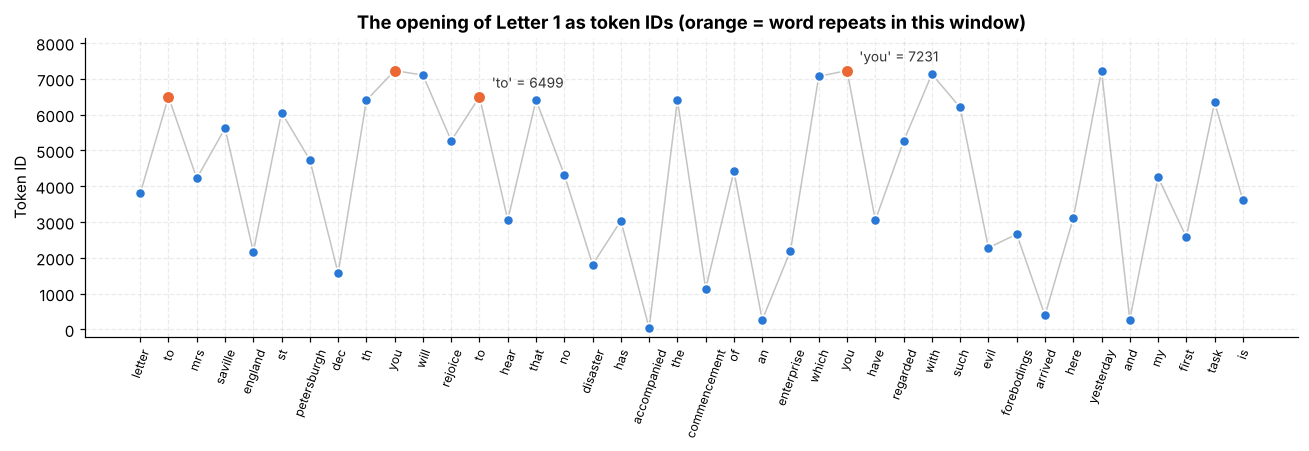

In [10]:
# locate the start of the story: the words 'letter to mrs saville'
start = next(i for i in range(nWords-3) if words[i:i+4] == ['letter','to','mrs','saville'])
story = words[start:start+40]
storyIDs = encoder(story, word2idx)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(storyIDs, color=GREY, lw=1, alpha=.5, zorder=1)
ax.scatter(range(len(storyIDs)), storyIDs, s=46, color=BLUE, edgecolor='white', lw=1.2, zorder=2)

# highlight words that repeat in this window
for w in {w for w in story if story.count(w) > 1}:
    locs = [i for i, s in enumerate(story) if s == w]
    ax.scatter(locs, storyIDs[locs], s=70, color=ORANGE, edgecolor='white', lw=1.2, zorder=3)
    ax.annotate(f"'{w}' = {word2idx[w]}", (locs[-1], word2idx[w]), xytext=(8, 6),
                textcoords='offset points', fontsize=9, color='#333')

ax.set_xticks(range(len(story)))
ax.set_xticklabels(story, rotation=70, fontsize=8)
ax.set(ylabel='Token ID', ylim=(-200, nLex+900),
       title='The opening of Letter 1 as token IDs (orange = word repeats in this window)')
plt.tight_layout()
plt.show()

---
## 8 · Generating text with zero knowledge 🎲

A language model's job is to pick the **next token**. Before any learning, we can still "generate" by picking token IDs at random and decoding them. This gives us a **baseline**: whatever a trained model produces must be better than this.

### 8a · Uniform random tokens

`np.random.randint(0, nLex, 10)` draws 10 IDs, each equally likely. Decoding gives word salad: real words, no grammar, no meaning.

In [11]:
# random tokens (every word in the vocabulary is equally likely)
randomTokens = np.random.randint(0,len(vocab),10)
print(randomTokens)
decoder(randomTokens, idx2word)

[ 860 5390 5226 5191 3772 3092 5734 6265  466 5334]


'cabinets request recur recall learned helpless september surprise astounded renamed'

### 8b · Brownian-noise tokens (a random walk)

**Brown noise** is the cumulative sum of random ±1 steps: each value is the previous value plus or minus one. Here we generate **50** steps and add a random starting ID, so consecutive tokens are always **neighbours in the vocabulary**.

```text
steps:      +1 +1 -1 +1 -1 -1 ...
walk:  s, s+1, s+2, s+1, s+2, s+1, s, ...
```

Because the vocabulary is sorted alphabetically, neighbours share a prefix, so the decoded text loops over words that *look* alike (with this seed: *strong, stronger, strongly, struck, structure, struggle, student*) but still has no meaning. The plot compares the two kinds of noise.

> 💡 Lesson: smoothness in **ID space** is not smoothness in **meaning space**. Embeddings (next lesson) build a space where nearby really does mean similar.

In [12]:
# Brown noise: cumulative sum of random +1/-1 steps
BrownNoise = np.cumsum(np.random.choice([1,-1],50))

# shift the walk to a random starting point in the vocabulary
BrownianRandomTokens = BrownNoise+np.random.choice(nLex,1)

# keep the IDs inside the valid range [0, nLex-1] (guards against walking off the ends)
BrownianRandomTokens = np.clip(BrownianRandomTokens, 0, nLex-1)
print(BrownianRandomTokens)

[6165 6166 6165 6166 6165 6164 6163 6164 6163 6164 6163 6162 6161 6160
 6159 6158 6157 6156 6157 6158 6157 6156 6155 6156 6155 6156 6157 6158
 6159 6160 6159 6158 6157 6156 6155 6156 6155 6154 6155 6154 6155 6154
 6155 6154 6153 6154 6155 6156 6157 6158]


In [13]:
decoder( BrownianRandomTokens, idx2word)

'struggled student struggled student struggled struggle structure struggle structure struggle structure struck strove strongly stronger strong striving strive striving strong striving strive strife strive strife strive striving strong stronger strongly stronger strong striving strive strife strive strife strict strife strict strife strict strife strict strewed strict strife strive striving strong'

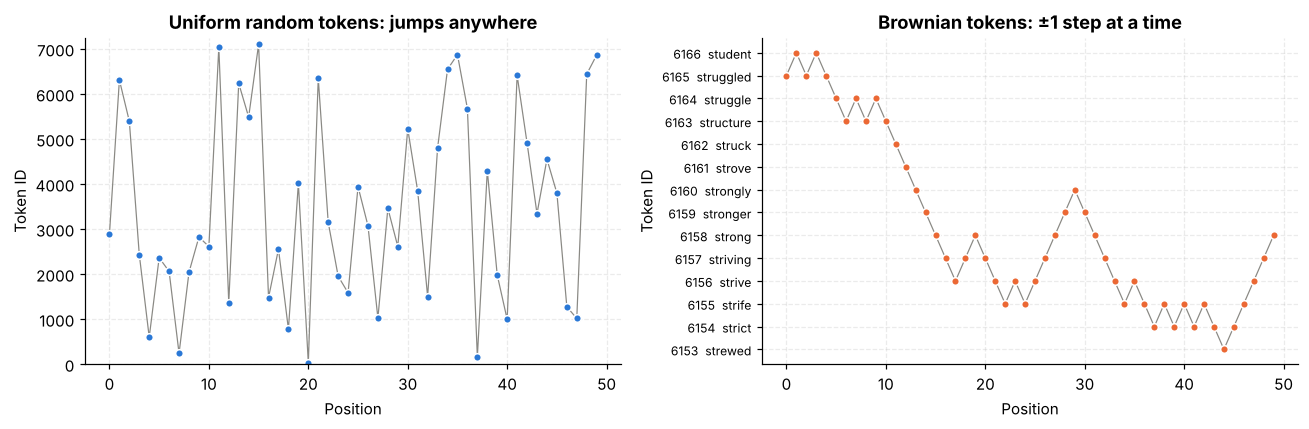

In [14]:
uniformTokens = np.random.randint(0, nLex, 50)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(uniformTokens, 'o-', color=GREY, ms=5, lw=.8, mfc=BLUE, mec='white')
axs[0].set(title='Uniform random tokens: jumps anywhere', xlabel='Position', ylabel='Token ID', ylim=(0, nLex))

axs[1].plot(BrownianRandomTokens, 'o-', color=GREY, ms=5, lw=.8, mfc=ORANGE, mec='white')
axs[1].set(title='Brownian tokens: ±1 step at a time', xlabel='Position', ylabel='Token ID')
lo, hi = BrownianRandomTokens.min(), BrownianRandomTokens.max()
axs[1].set_yticks(range(lo, hi+1))
axs[1].set_yticklabels([f'{i}  {idx2word[i]}' for i in range(lo, hi+1)], fontsize=8)

plt.tight_layout()
plt.show()

---
## 9 · 📊 Distribution of word length

How many characters do the words in *Frankenstein* have? We count the length of every word (**tokens**, with repeats) and of every **unique** word (vocabulary).

> ⚠️ **Bug fix vs. the original:** `charcounts = np.zeros(int(np.max(numChars)))` has indices `0 … max-1`, so the loop never counted words of the **maximum** length (the 18-letter *characteristically*). The array now has `max + 1` slots.

In [15]:
# length of every word in the book
numChars = np.zeros(nWords)
for i ,w in enumerate(words):
  numChars[i] = len(w)

# count number of words with those chars (index = word length)
maxLen = int(np.max(numChars))
charcounts = np.zeros(maxLen+1)
for i in range(maxLen+1):
  charcounts[i] = np.sum(numChars==i)

# same thing for the unique words in the vocabulary
vocabLens = np.array([len(w) for w in vocab])
vocabcounts = np.array([np.sum(vocabLens==i) for i in range(maxLen+1)])

print(f'mean word length: {numChars.mean():.2f} characters (tokens) | {vocabLens.mean():.2f} (unique words)')
print('longest words:', sorted(vocab, key=len)[-4:])

mean word length: 4.65 characters (tokens) | 7.32 (unique words)
longest words: ['inextinguishable', 'perpendicularity', 'unenforceability', 'characteristically']


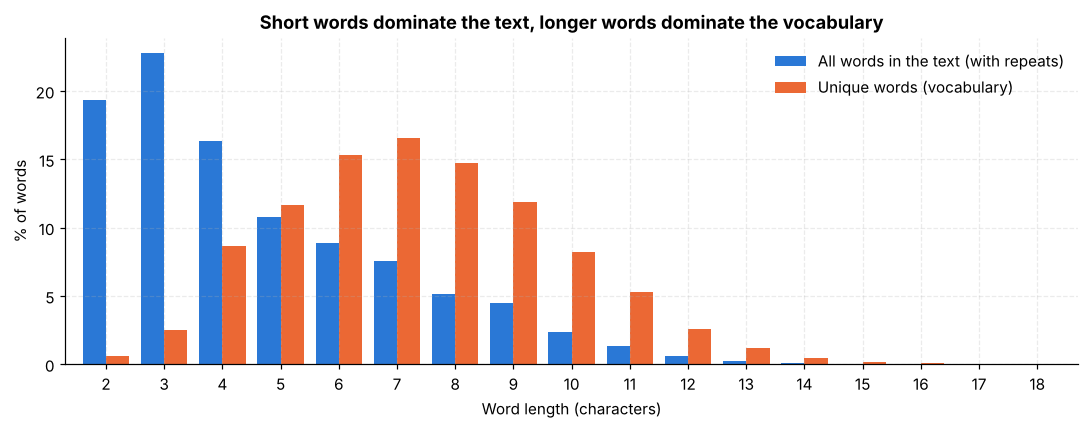

In [16]:
L = np.arange(maxLen+1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(L-0.2, 100*charcounts/nWords, width=0.4, color=BLUE, label='All words in the text (with repeats)')
ax.bar(L+0.2, 100*vocabcounts/nLex,  width=0.4, color=ORANGE, label='Unique words (vocabulary)')
ax.set(xlabel='Word length (characters)', ylabel='% of words', xticks=L[2:], xlim=(1.3, maxLen+0.7),
       title='Short words dominate the text, longer words dominate the vocabulary')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading the plot:** the most common word length *in the running text* is 3 (*the, and, was*), but the most common length *in the vocabulary* is 7. A few short function words are repeated thousands of times, while the long, content-bearing words are many but individually rare. This imbalance is the reason modern tokenizers split long rare words into reusable **subword** pieces.

---
## 10 · 📊 Word frequencies, Zipf's law and Heaps' law

`collections.Counter` counts how often each word appears. Three views:

1. **Top 20 words:** almost all are *function words* (*the, and, of, to*). Note *my* and *me* in the top 10: much of the novel is told in the first person.
2. **Zipf's law:** plotting frequency against rank on log-log axes gives a nearly straight line, `frequency ∝ 1 / rank`. The most common word is about twice as common as the 2nd, three times the 3rd, and so on.
3. **Heaps' law:** the vocabulary keeps growing as we read more text and never levels off. More data always brings new words, so a word-level vocabulary has no natural size limit.

In [17]:
freq = Counter(words)
top = freq.most_common(20)
ranks = np.arange(1, nLex+1)
counts = np.array(sorted(freq.values(), reverse=True))

hapax = sum(1 for c in freq.values() if c == 1)
print(f'{hapax:,} of {nLex:,} words ({100*hapax/nLex:.0f}%) appear only once ("hapax legomena")')
for k in (10, 100, 1000):
    print(f'top {k:>4} words cover {100*counts[:k].sum()/nWords:.0f}% of the text')

# vocabulary growth as we read through the book
seen, growth = set(), []
for w in words:
    seen.add(w)
    growth.append(len(seen))

3,076 of 7,243 words (42%) appear only once ("hapax legomena")
top   10 words cover 26% of the text
top  100 words cover 53% of the text
top 1000 words cover 80% of the text


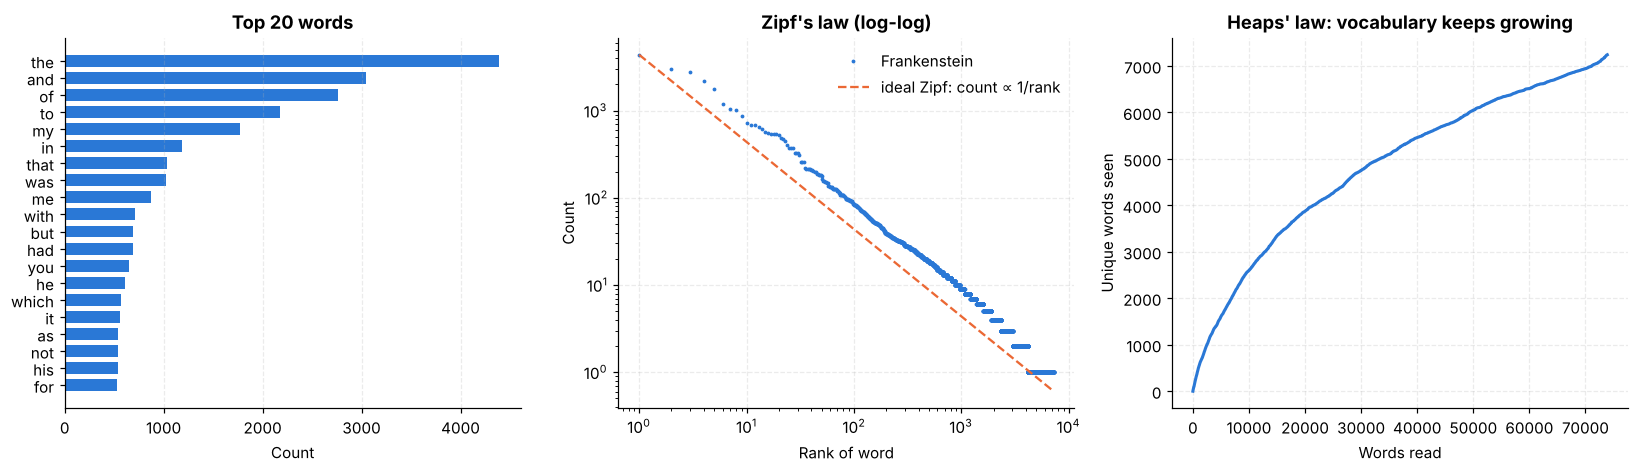

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))

# (1) top 20 words
axs[0].barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color=BLUE, height=0.7)
axs[0].set(title='Top 20 words', xlabel='Count')
axs[0].grid(axis='y', visible=False)

# (2) Zipf
axs[1].loglog(ranks, counts, '.', color=BLUE, ms=3, label='Frankenstein')
axs[1].loglog(ranks, counts[0]/ranks, '--', color=ORANGE, lw=1.5, label='ideal Zipf: count ∝ 1/rank')
axs[1].set(title="Zipf's law (log-log)", xlabel='Rank of word', ylabel='Count')
axs[1].legend(frameon=False)

# (3) Heaps
axs[2].plot(np.arange(1, nWords+1), growth, color=BLUE, lw=2)
axs[2].set(title="Heaps' law: vocabulary keeps growing", xlabel='Words read', ylabel='Unique words seen')

plt.tight_layout()
plt.show()

---
## 11 · Encoding a novel sentence 🆕

A real tokenizer must handle text it has never seen. We take a new sentence and push it through **the same cleaning and splitting** (lowercase + split on punctuation/whitespace).

> ⚠️ Note that `i` is still produced here because we did **not** apply the `len > 1` filter to the new sentence, but the vocabulary was built **with** that filter. Inconsistent preprocessing between "training" and "inference" is a classic source of tokenizer bugs.

In [19]:
sentence = ' Hi I chatgpt am going home this week'

# same split as the book, then remove empty items
words_new = re.split(puncts4re, sentence.lower())
words_new = [item.strip() for item in words_new if item.strip()]

words_new

['hi', 'i', 'chatgpt', 'am', 'going', 'home', 'this', 'week']

The plain encoder fails with **`KeyError: 'hi'`**. Three words are unknown:

| Word | Why it is missing |
|------|-------------------|
| `hi` | never used in an 1818 novel |
| `i` | removed from the vocabulary by the `len > 1` filter |
| `chatgpt` | a word that did not exist until 2022 |

The `try/except` below catches the error so that **Run all** does not stop here. The point is the same: a closed vocabulary breaks on new words.

In [20]:
try:
    encoder(words_new, word2idx)
except KeyError as err:
    # gives an error because 'hi', 'i' and 'chatgpt' are not in the vocabulary
    print('KeyError:', err, '-> this word is not in the vocabulary')

unknown = [w for w in words_new if w not in word2idx]
print('out-of-vocabulary words:', unknown)

KeyError: 'hi' -> this word is not in the vocabulary
out-of-vocabulary words: ['hi', 'i', 'chatgpt']


---
## 12 · A new encoder with an `<|unk|>` token 🛟

The simplest fix is a **special token** for anything unknown. We copy both dictionaries and add `<|unk|>` at the end of the vocabulary. The new encoder checks `if w in encode_dict` and falls back to the `<|unk|>` ID otherwise.

> ⚠️ **Off-by-one fix vs. the original:** the original used `len(word2idx) + 1` (= 7244) as the new ID, which skips 7243 and leaves a hole in the ID range. The next free ID is simply `len(word2idx)` (= 7243), so IDs stay contiguous `0 … nLex`. This matters later, when IDs index rows of an embedding matrix.

The `<|...|>` style is the same one GPT models use for special tokens such as `<|endoftext|>`.

In [21]:
word2idx_new = word2idx.copy()
idx2word_new = idx2word.copy()

# next free ID = len(word2idx)  (keeps IDs contiguous: 0 ... nLex)
unkID = len(word2idx)
word2idx_new['<|unk|>'] = unkID
idx2word_new[unkID] = '<|unk|>'

print(f"'<|unk|>' -> {word2idx_new['<|unk|>']}   |   new vocabulary size: {len(word2idx_new):,}")

'<|unk|>' -> 7243   |   new vocabulary size: 7,244


In [22]:
#Encoder Function
def encoder_new(words, encode_dict):

    # initialize a vector of numerical indices
    idxs = np.zeros(len(words), dtype=int)

    # loop through the words and find their token in the vocab
    for i,w in enumerate(words):
      if w in encode_dict:
        idxs[i] = encode_dict[w]
      else:
        # unknown word -> fall back to the special <|unk|> token
        idxs[i] = encode_dict['<|unk|>']

    # return the indices!
    return idxs

In [23]:
tokenidx = encoder_new(words_new,word2idx_new)
print(tokenidx)
print(decoder(tokenidx, idx2word_new))

[7243 7243 7243  246 2879 3150 6444 7034]
<|unk|> <|unk|> <|unk|> am going home this week


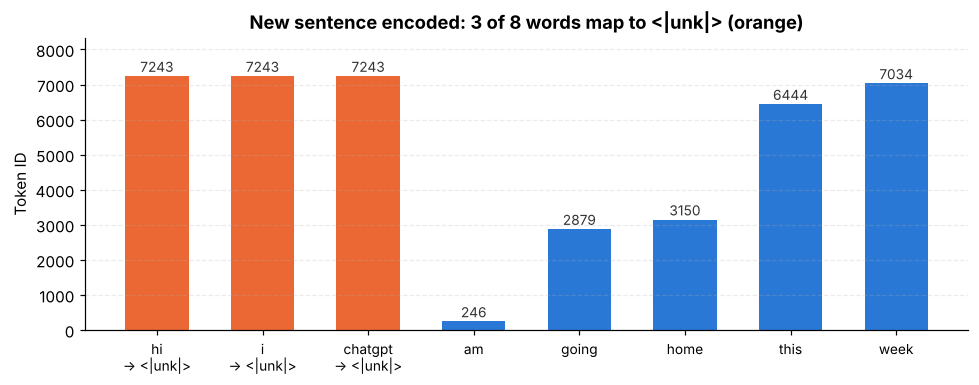

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.6))
isUnk = tokenidx == unkID
colors = [ORANGE if u else BLUE for u in isUnk]
bars = ax.bar(range(len(tokenidx)), tokenidx, color=colors, width=0.6)
for i, (w, t) in enumerate(zip(words_new, tokenidx)):
    ax.text(i, t + 120, str(t), ha='center', fontsize=9, color='#333')
ax.set_xticks(range(len(words_new)))
ax.set_xticklabels([f'{w}\n→ <|unk|>' if u else w for w, u in zip(words_new, isUnk)], fontsize=9)
ax.set(ylabel='Token ID', ylim=(0, nLex*1.15),
       title=f'New sentence encoded: {isUnk.sum()} of {len(tokenidx)} words map to <|unk|> (orange)')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

The encoder no longer crashes, but **information is lost**: `hi`, `i` and `chatgpt` all decode to the same `<|unk|>`, so the round trip is broken for them. That trade-off is why modern LLMs use **subword tokenizers** (Byte Pair Encoding): an unseen word such as *chatgpt* is split into known pieces like `chat` + `g` + `pt`, so nothing ever needs to be `<|unk|>`.

---
## 13 · Summary ✅

| Quantity | Value |
|----------|-------|
| Characters downloaded | 446,582 |
| Words after cleaning | 73,888 |
| Unique words (vocabulary) | 7,243 (+1 with `<|unk|>`) |
| Words that appear only once | 3,076 (42% of the vocabulary) |
| Text covered by the 100 most common words | 53% |
| OOV words in *"Hi I chatgpt am going home this week"* | 3 of 8 |

**What we did**
1. Downloaded a real book and cleaned it (encoding artefacts, non-ASCII, digits, case).
2. Split it into words with a punctuation + whitespace regex.
3. Built a 7,243-word vocabulary with reversible `word2idx` / `idx2word` tables.
4. Wrote a NumPy-based encoder/decoder and verified the round trip on the whole novel.
5. Generated zero-knowledge "text" from uniform and Brownian random tokens.
6. Measured word lengths, frequencies, Zipf's law and vocabulary growth.
7. Hit the out-of-vocabulary problem and solved it (partly) with an `<|unk|>` token.

**Why it matters for an LLM**
* The vocabulary size sets the size of the model's **embedding table** and **output softmax**.
* Zipf + Heaps explain why **word-level vocabularies don't scale**: they grow forever and most entries are rare.
* `<|unk|>` keeps the encoder alive but throws information away; **subword tokenization (BPE)** is the real fix.
* Token IDs are labels, not quantities: **embeddings** must give them meaning.

**Next:** lesson 03, *Vector Representation Spaces*: turning these integer IDs into learned vectors.